# 01. Data overview: multi-stakeholder perception survey

**Business question.** A brand team needs to know what drives advocacy for its therapy among each stakeholder group,
and wants the analysis repeatable every survey wave rather than rebuilt by hand. Before running the driver framework we
check the survey: sample sizes, data quality, the outcome distribution, how each group rates the 24 attributes, and how
strongly ratings are correlated with each other (halo), which matters for interpreting correlation-based importance.

The survey is synthetic (`src/generate_data.py`) and concerns a fictional therapy, Velarex.

In [1]:
import os
# Single-threaded BLAS: avoids thread oversubscription and keeps timings reproducible on shared machines.
for var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(var, "1")
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("../src")
from plotting import apply_style, PALETTE
from generate_data import ATTRIBUTES, OUTCOME, OUTCOME_LABELS
apply_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.width", 160)

RAW = Path("../data/raw/stakeholder_survey.csv")
PROCESSED = Path("../data/processed"); PROCESSED.mkdir(parents=True, exist_ok=True)
FIGS = Path("../reports/figures"); FIGS.mkdir(parents=True, exist_ok=True)
DRIVERS = list(ATTRIBUTES)
GROUPS = ["Physicians", "Pharmacists", "Patients", "Payers"]

In [2]:
df = pd.read_csv(RAW)
print(f"{len(df):,} respondents x {df.shape[1]} columns; {len(DRIVERS)} attribute ratings + outcome")
df.head()

2,350 respondents x 28 columns; 24 attribute ratings + outcome


,respondent_id,stakeholder_group,region,clinical_efficacy,speed_of_onset,durability_of_response,safety_profile,tolerability,drug_interactions,dosing_convenience,...,medical_info_responsiveness,educational_materials,real_world_evidence,guideline_endorsement,peer_recommendation,value_for_money,cost_effectiveness_data,company_reputation,digital_resources,outcome_score
0,R00001,Physicians,Region C,7.000,7.000,6.000,7.000,NaN,7.000,7.000,...,5.000,4.000,5.000,6.000,10.000,10.000,8.000,10.000,5.000,6
1,R00002,Physicians,Region C,7.000,6.000,5.000,8.000,7.000,NaN,7.000,...,8.000,8.000,4.000,8.000,7.000,7.000,6.000,8.000,7.000,6
2,R00003,Physicians,Region A,6.000,5.000,6.000,7.000,6.000,9.000,NaN,...,6.000,7.000,5.000,9.000,8.000,7.000,7.000,8.000,7.000,5
3,R00004,Physicians,Region C,10.000,6.000,6.000,8.000,6.000,6.000,8.000,...,6.000,7.000,4.000,8.000,8.000,7.000,6.000,5.000,5.000,8
4,R00005,Physicians,Region A,7.000,7.000,6.000,9.000,3.000,7.000,7.000,...,8.000,7.000,6.000,4.000,4.000,8.000,6.000,6.000,6.000,7


In [3]:
sizes = df.groupby("stakeholder_group", sort=False).agg(
    respondents=("respondent_id", "size"),
    outcome_mean=(OUTCOME, "mean"), outcome_sd=(OUTCOME, "std"))
sizes["outcome_measured"] = sizes.index.map(OUTCOME_LABELS)
sizes

,respondents,outcome_mean,outcome_sd,outcome_measured
stakeholder_group,,,,
Physicians,600,6.298,1.991,prescribing intent
Pharmacists,400,6.253,1.958,likelihood to recommend
Patients,1200,6.282,1.972,likelihood to recommend
Payers,150,6.253,2.034,likelihood to grant preferred formulary status


## Data quality

Ratings use a 1-10 scale; "don't know" answers are stored as missing. The framework uses pairwise-complete
observations, so a missing rating removes the respondent from that attribute only.

In [4]:
missing = df[DRIVERS].isna().mean().rename("missing_share")
print(f"overall missing share: {df[DRIVERS].isna().to_numpy().mean():.2%}; "
      f"respondents with at least one missing rating: {df[DRIVERS].isna().any(axis=1).mean():.1%}")
print("out-of-range ratings:", int(((df[DRIVERS] < 1) | (df[DRIVERS] > 10)).sum().sum()))
print("duplicate respondent ids:", df["respondent_id"].duplicated().sum())
missing.describe().to_frame().T

overall missing share: 2.99%; respondents with at least one missing rating: 51.9%
out-of-range ratings: 0
duplicate respondent ids: 0


,count,mean,std,min,25%,50%,75%,max
missing_share,24.000,0.030,0.004,0.023,0.028,0.029,0.032,0.037


## Outcome distribution by group

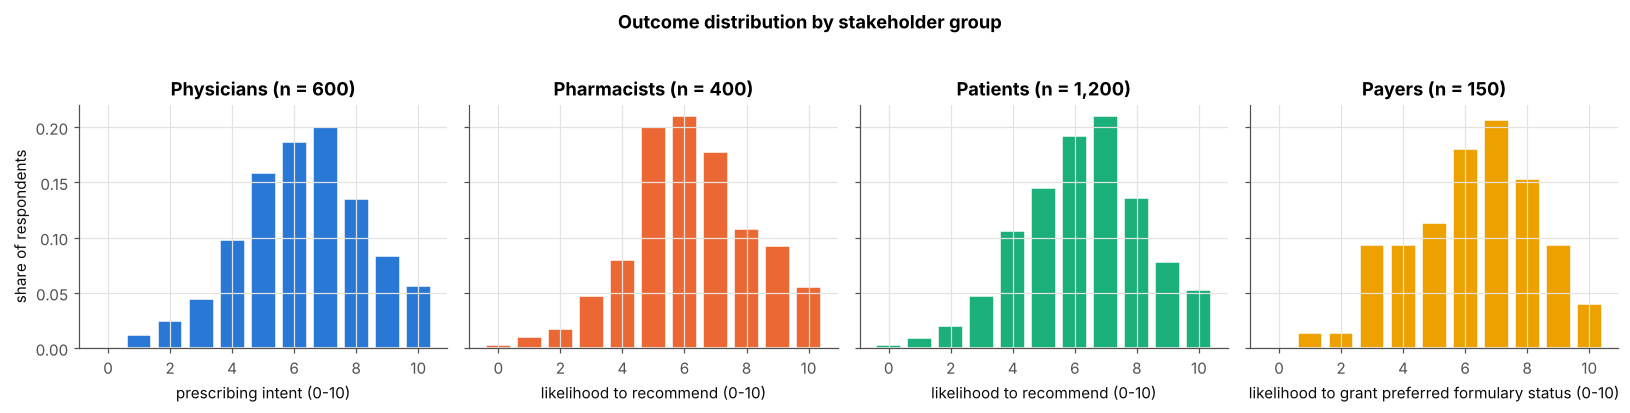

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for ax, g, c in zip(axes, GROUPS, PALETTE):
    s = df.loc[df["stakeholder_group"] == g, OUTCOME]
    counts = s.value_counts(normalize=True).reindex(range(11), fill_value=0)
    ax.bar(counts.index, counts.values, color=c, edgecolor="white")
    ax.set(title=f"{g} (n = {len(s):,})", xlabel=f"{OUTCOME_LABELS[g]} (0-10)")
    ax.set_xticks(range(0, 11, 2))
axes[0].set_ylabel("share of respondents")
fig.suptitle("Outcome distribution by stakeholder group", fontweight="bold", y=1.03)
fig.tight_layout()
fig.savefig(FIGS / "01_outcome_distribution.png")
plt.show()

## Attribute performance by group

Mean rating per attribute and group. This is the "performance" axis of the quadrant chart.

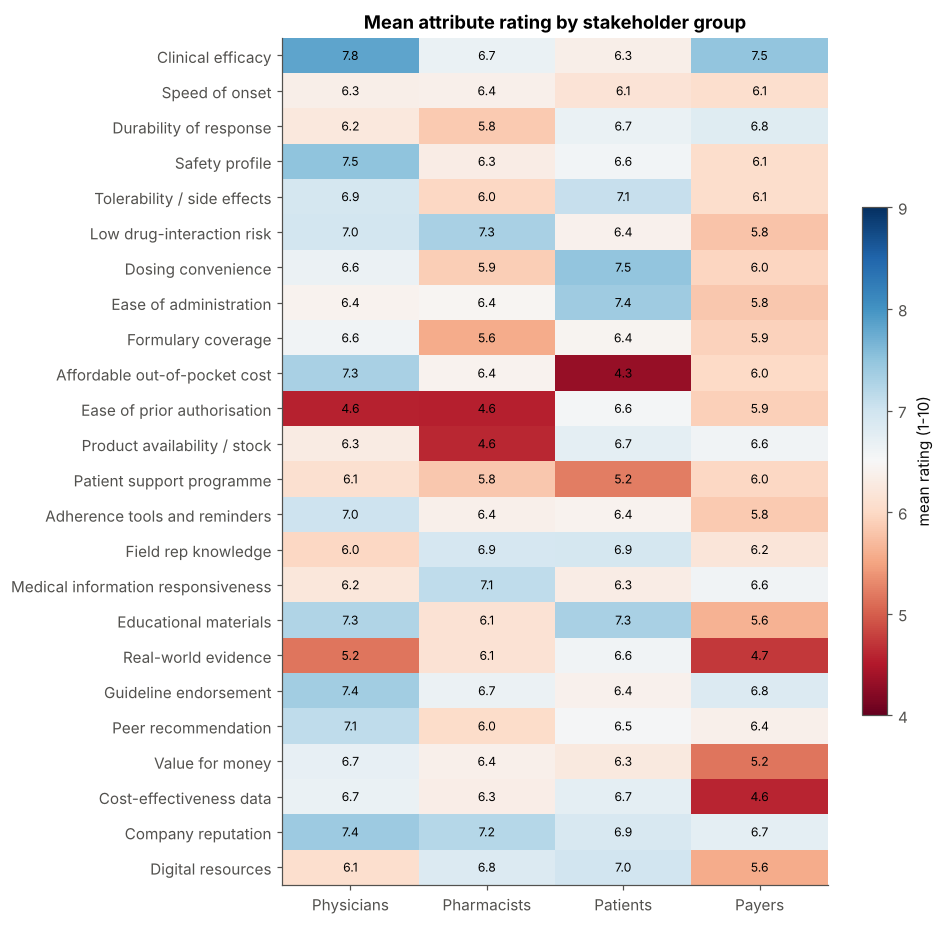

In [6]:
perf = df.groupby("stakeholder_group")[DRIVERS].mean().T[GROUPS]
perf.index = [ATTRIBUTES[a] for a in perf.index]
fig, ax = plt.subplots(figsize=(8, 10))
im = ax.imshow(perf, cmap="RdBu", vmin=4, vmax=9, aspect="auto")
ax.set_xticks(range(len(GROUPS)), GROUPS)
ax.set_yticks(range(len(perf)), perf.index)
ax.grid(False)
for i in range(perf.shape[0]):
    for j in range(perf.shape[1]):
        ax.text(j, i, f"{perf.iloc[i, j]:.1f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.6, label="mean rating (1-10)")
ax.set_title("Mean attribute rating by stakeholder group")
fig.savefig(FIGS / "01_performance_heatmap.png")
plt.show()

In [7]:
low_high = pd.DataFrame({g: {"lowest rated": perf[g].idxmin() + f" ({perf[g].min():.2f})",
                             "highest rated": perf[g].idxmax() + f" ({perf[g].max():.2f})",
                             "average rating": f"{perf[g].mean():.2f}"} for g in GROUPS})
low_high

,Physicians,Pharmacists,Patients,Payers
lowest rated,Ease of prior authorisation (4.59),Ease of prior authorisation (4.56),Affordable out-of-pocket cost (4.33),Cost-effectiveness data (4.61)
highest rated,Clinical efficacy (7.82),Low drug-interaction risk (7.32),Dosing convenience (7.48),Clinical efficacy (7.49)
average rating,6.61,6.25,6.53,6.03


## Halo check: how correlated are the attribute ratings?

Respondents who like a brand tend to rate it well on everything. A high average inter-item correlation inflates every
driver's correlation with the outcome, which is why notebook 03 checks the correlation ranking against relative
weights (which partial out shared variance).

In [8]:
halo = {}
for g in GROUPS:
    c = df.loc[df["stakeholder_group"] == g, DRIVERS].corr().to_numpy()
    halo[g] = c[np.triu_indices_from(c, k=1)].mean()
halo = pd.Series(halo, name="mean inter-attribute r").to_frame()
alphas = {}
for g in GROUPS:
    x = df.loc[df["stakeholder_group"] == g, DRIVERS].dropna()
    k = x.shape[1]
    alphas[g] = k / (k - 1) * (1 - x.var().sum() / x.sum(axis=1).var())
halo["cronbach_alpha"] = pd.Series(alphas)
halo

,mean inter-attribute r,cronbach_alpha
Physicians,0.088,0.713
Pharmacists,0.085,0.694
Patients,0.090,0.702
Payers,0.099,0.750


## Findings

* **2,350 respondents** across four groups: Physicians 600, Pharmacists 400, Patients 1,200, Payers 150. Each rated
  24 attributes (1-10) and gave a 0-10 outcome; outcome means sit between 6.25 and 6.30 in every group.
* Data quality: 2.99% of ratings are "don't know"; because they are scattered, 51.9% of respondents have at least one,
  which is why the framework uses pairwise-complete correlations instead of dropping incomplete respondents.
  No out-of-range ratings or duplicate IDs.
* The lowest-rated attribute differs by group: ease of prior authorisation for physicians (4.59) and pharmacists
  (4.56), affordable out-of-pocket cost for patients (4.33) and cost-effectiveness data for payers (4.61).
* Average attribute rating (the performance threshold used later): Physicians 6.61, Pharmacists 6.25,
  Patients 6.53, Payers 6.03.
* The halo is modest (mean inter-attribute r 0.085 to 0.099; Cronbach's alpha 0.69 to 0.75), so correlation
  importance should not be heavily inflated; notebook 03 verifies this with relative weights.